# 09 — Remote shared-memory (DSMEM) latency on the H100 versus cluster size

**Goal.** Measure, on one H100 NVL at a locked 1635 MHz SM clock, how long one thread waits for a load from the shared memory of *another* thread block in the same thread-block cluster (a distributed-shared-memory, DSMEM, access), and whether that time depends on:
- the cluster size (2 to 16 CTAs);
- which two SMs talk (TPC, GPC, rank distance);
- the scheduling policy;
- the PTX form of the load (address form, generic pointer, memory-model qualifiers, width).

Next to it we measure:
- the same path pointed at the CTA's own memory;
- the latency per request when one SM streams a remote buffer with many loads in flight;
- how long a *store* into another CTA's shared memory takes to become visible to that CTA, for five ways of writing it.

Local shared memory, an L2 hit and an HBM access are measured in the same binary as references.

Why it matters: a cluster of up to 16 CTAs shares its shared memories through an SM-to-SM network inside one GPC. Whether that network has a single, flat latency or a distance structure determines how cluster algorithms (halo exchange, reductions, producer/consumer pipelines) should place data and how much a remote access costs relative to L2 and HBM.

## 2. Background

**Thread-block clusters and DSMEM.** On Hopper, a kernel can be launched with a *cluster* dimension: groups of up to 8 CTAs (16 with the non-portable attribute) are guaranteed to run at the same time on SMs of one GPC (graphics processing cluster). Every CTA of a cluster can read, write and perform atomics on the shared memory of every other CTA of the cluster. The combined shared memories form the `.shared::cluster` address space; each byte still lives in the SRAM of exactly one SM. A remote access leaves the issuing SM, crosses the GPC's SM-to-SM network to the owning SM, is served by that SM's shared-memory pipeline, and the reply returns the same way.

**Addressing.** `mapa.shared::cluster.u32 r, a, rank` converts the shared-memory offset `a` of the executing CTA into the cluster address of the same offset in CTA `rank`; `ld.shared::cluster` reads that address. `cluster.map_shared_rank(p, rank)` in CUDA C++ returns a *generic* pointer to the same location. On this toolchain, both compile to a generic `LD.E` whose 64-bit address is the 32-bit cluster address in the low word and the shared-window base (`SR_SWINHI`) in the high word. The `mapa` itself compiles to a byte permute (`PRMT`): the target rank is written into bits 24–31 of the 32-bit address.

```
mapa.shared::cluster.u32  base, smem_off, dst;   // → PRMT base, dst, 0x654, smem_off
ld.shared::cluster.u32    v, [base + v];          // → IADD; MOV hi = SR_SWINHI; LD.E v, [lo:hi]
```

**Existence rule.** A remote access is only defined while the target CTA exists, so every protocol starts and ends with `cluster.sync()` (`barrier.cluster.arrive.release` + `wait.acquire`).

**Placement and scheduling policy.** All CTAs of a cluster run on distinct SMs of one GPC. The scheduling-policy launch attribute (`Default`, `Spread`, `LoadBalancing`) is a preference given to the hardware. With 200 KB of dynamic shared memory per CTA only one CTA fits on an SM, so the policies cannot co-locate CTAs and differ at most in which SMs are chosen. This H100 has 8 GPCs of 12–18 SMs; two SMs form a TPC (SMs 2t and 2t+1). In a cluster's first wave, ranks 2k and 2k+1 sit on one TPC.

**Stores and visibility.** A remote store is posted: the issuing thread continues at once, and the value appears in the destination's memory some time later. The destination learns about it either by polling the word, or through an *mbarrier*. With `st.async` / `red.async` the store carries a byte count that completes a transaction on an mbarrier in the destination CTA, and the consumer waits on that barrier (`mbarrier.try_wait`) instead of the data. A `.release` store orders all earlier memory operations of the thread before the store; on this GPU every release compiles to a GPU-scope memory barrier followed by a strong store.

## 3. Experimental setup

In [1]:
%matplotlib inline
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, "src")
from common09 import EXP, MANDATORY, RES, load, read_run, runs, sm_map, stats

QUICK = False
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # fixed categorical order
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.prop_cycle": plt.cycler(color=C),
                     "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6})
pd.set_option("display.width", 200)
pd.set_option("display.precision", 1)

CH, R_CH = load("chase", QUICK, usecols=MANDATORY + ["cs", "policy", "variant", "chain", "cluster_id", "src_rank", "dst_rank",
                                                      "smid_src", "smid_dst", "gpc_src", "gpc_dst", "cycles_per_hop"])
FI, R_FI = load("fine", QUICK)
LO, R_LO = load("loaded", QUICK)
LH, _ = load("loaded_hist", QUICK)
VI, R_VI = load("visibility", QUICK)
BA, R_BA = load("baselines", QUICK)
SMAP = sm_map()
MHZ = float(CH.sm_clock_mhz.median())
CSS = [1, 2, 4, 8, 16]
POL = ["Default", "Spread", "LoadBalancing"]
REM = CH[CH.pair != "self"]
MAIN = REM[(REM.variant == "ld_cluster") & (REM.chain == "stride1")]
REF = BA.groupby(["level", "chain"]).cycles_per_hop.median()
LDS, L2, HBM = REF[("lds_idx", "stride1")], REF[("l2_chase", "random")], REF[("dram_chase", "random")]
SELF1 = CH[(CH.cs == 1) & (CH.variant == "ld_cluster") & (CH.chain == "stride1")].cycles_per_hop.median()


def ns_axis(ax, which="y"):
    """Secondary axis in ns at the run's SM clock (same quantity as the cycle axis)."""
    f = (lambda c: c / MHZ * 1e3, lambda n: n * MHZ / 1e3)
    sec = ax.secondary_yaxis("right", functions=f) if which == "y" else ax.secondary_xaxis("top", functions=f)
    sec.set_ylabel("ns") if which == "y" else sec.set_xlabel("ns")
    return sec

In [2]:
# Device and fixed configuration, from the mandatory CSV columns of the runs analysed here
r0 = CH.iloc[0]
ncu = pd.read_csv(f"{RES}/09__dsmem_latency__ncu_k1.csv") if not QUICK else None
ncu_mhz = (f"{ncu[ncu.run_id == ncu.run_id.max()]['sm__cycles_elapsed.avg.per_second'].astype(float).median() / 1e6:.0f} MHz "
           "(ncu sm__cycles_elapsed.avg.per_second, profiled K1 launches)") if ncu is not None else "-"
display(pd.DataFrame({"": [r0.gpu_name, r0.sm_count, f"{MHZ:.0f} MHz (NVML after every launch, median; locked at 1635 MHz)", ncu_mhz,
                           f"{r0.mem_clock_mhz} MHz", "400 W", "enabled / disabled", r0.cuda_version, r0.driver_version,
                           "-arch=sm_90a -O3 -lineinfo"]},
                     index=["GPU", "SMs", "SM clock", "SM clock under ncu", "memory clock", "power limit", "ECC / MIG", "CUDA",
                            "driver", "nvcc"]))
# Runs, recorded launches, rows and discarded launches
import os
dpath = f"{RES}/09__dsmem_latency__discards.csv"  # written only when a launch is discarded (empty: none ever)
disc = pd.read_csv(dpath) if os.path.getsize(dpath) else pd.DataFrame(columns=["run_id", "reason"])
inv = []
for name, df, run in [("K1 chase + K1-fine", CH, R_CH), ("K1f loaded", LO, R_LO), ("K2 visibility", VI, R_VI), ("K3 baselines", BA, R_BA)]:
    d = disc[disc.run_id == run]
    inv.append([name, run, df.launch_idx.nunique(), len(df), int((d.reason == "placement").sum()), int((d.reason == "clock").sum())])
inv.append(["K1-fine (same run as K1)", R_FI, FI.launch_idx.nunique(), len(FI), "", ""])
display(pd.DataFrame(inv, columns=["kernel", "run_id", "recorded launches", "rows", "discarded: placement", "discarded: clock"]).set_index("kernel"))

,
GPU,NVIDIA H100 NVL
SMs,132
SM clock,"1635 MHz (NVML after every launch, median; loc..."
SM clock under ncu,1591 MHz (ncu sm__cycles_elapsed.avg.per_secon...
memory clock,2619 MHz
power limit,400 W
ECC / MIG,enabled / disabled
CUDA,12.9
driver,580.126.20
nvcc,-arch=sm_90a -O3 -lineinfo


,run_id,recorded launches,rows,discarded: placement,discarded: clock
kernel,,,,,
K1 chase + K1-fine,2026-10-26T03:29:45.158+00:00,750,1091400,0,0
K1f loaded,2026-10-26T03:31:25.923+00:00,25,36380,0,0
K2 visibility,2026-10-26T03:31:30.746+00:00,350,2867200,0,0
K3 baselines,2026-10-26T03:28:18.039+00:00,280,280,0,0
K1-fine (same run as K1),2026-10-26T03:29:45.158+00:00,25,1745920,,


**What is measured and how.**

- **Timer.** Every latency is a `%clock64` difference on the SM that issues the loads (one-way visibility uses `%globaltimer`, see K2). The closing clock read depends on the last loaded value (`and` with a runtime zero, then the clock read), so it cannot issue before the load has returned; this ordering was checked in the SASS of every timed loop.
- **Placement.** 1-D clusters of CS CTAs with 200 KB dynamic shared memory each, so exactly one CTA runs on an SM. Every CTA records `%smid`, `%clusterid` and `%cluster_ctarank`; a launch in which two ranks of a cluster shared an SM, or whose clock sample after the launch showed a throttle reason or a clock below the lock, would be discarded and repeated (counts above). SMs are mapped to GPCs with this device's SM→GPC map. Each launch holds max(20, one full wave) clusters: 132, 66, 30, 20 and 20 clusters for CS 1, 2, 4, 8 and 16. That is one full wave of clusters — every SM that can join a cluster of that size hosts a CTA — and two to three waves of different SM sets at CS 8 and 16.
- **K1, zero-load chase (one thread).** Each CTA writes a pointer chain into its own shared memory before a `cluster.sync()`:
  - stride 1: 1024 elements, element *i* points to *i* + 1;
  - random: a uniformly random single cycle over 16 KiB.

  Each element holds the byte offset of its successor. The source ranks take turns (separated by `cluster.sync()`, so only one SM of a cluster is active at a time). The active source chases every destination's chain, its own included: `mapa`, 64 untimed hops, then 4096 timed dependent hops (`v = ld [base + v]`, 16 unrolled hops per loop iteration). The fixed cost of the timer pair and loop exit is at most 0.05 cycles per hop and is not subtracted. After the chase the final offset is checked against the position computed on the host.
- **K1 variants.**

  | variant | load | SASS (per hop) |
  |---|---|---|
  | `ld_cluster` | `ld.shared::cluster.u32 v, [base + v]` | IADD, MOV, `LD.E` |
  | `ld_cluster_addr` | chain of absolute cluster addresses, `ld.shared::cluster.u32 v, [v]` | MOV, `LD.E` |
  | `ld_generic` | `*(uint32_t*)(map_shared_rank(p, dst) + v)` | 64-bit IADD, `LD.E` |
  | `ld_volatile` | `ld.volatile.shared::cluster.u32` | `LD.E.STRONG.SYS` |
  | `ld_relaxed` | `ld.relaxed.cluster.shared::cluster.u32` | `LD.E.STRONG.GPU` |
  | `ld_acquire` | `ld.acquire.cluster.shared::cluster.u32` | `LD.E.STRONG.GPU`, `CCTL.IVALL` |
  | `ld_u64` / `ld_v4` | 8-B / 16-B elements, `.u64` / `.v4.u32` (the extra words feed a sink off the chain) | `LD.E.64` / `LD.E.128` |

- **K1-fine.** Directly after each 4096-hop measurement of `ld_cluster` (stride 1, Default policy, first 4 clusters of every launch), 256 further hops are timed one by one. Each per-hop value includes one timer pair, measured alone in K3.
- **K1f, latency under load.** 1024 threads of the source CTA read 192 KiB of the destination's shared memory: per thread 6 groups of 8 independent 4-B loads, consecutive threads on consecutive words (each warp load is one 128-B line). One sample = `%clock64` from the start of a group until its 8 values have returned. A chip-wide lock lets only one source CTA stream at a time, so other clusters add no traffic. The 6144 samples per pair are reduced exactly: mean, p5, p50, p95, min, max per pair and launch, plus a histogram of every sample.
- **K2, store visibility.** Two ranks of a cluster ping-pong 1024 times: rank 0 stores epoch *e* into rank *p*'s shared memory, rank *p* sees it and stores *e* back, rank 0 sees it.
  - **Round trip.** `%clock64` on rank 0, in a version of the kernel without any global-timer read.
  - **One-way latency.** From `%globaltimer` stamps taken right before the store and right after the consumer sees the value (32-ns ticks; the mean over 1024 trials).
  - **Waiting.** The waiter polls its own word with a local `ld.volatile.shared` for the plain, release and exchange variants, and waits on its mbarrier for `st.async` / `red.async`.
  - **Placement.** Pairs (0, 1) — one TPC in a first-wave cluster — and, for CS ≥ 4, (0, CS − 1) on another TPC. 8 clusters ping-pong at the same time.
- **K3, references.** Run on one SM of each GPC, pinned with a claim block and without reserving its shared memory:
  - the K1 chains read with local `ld.shared`;
  - the timer pair alone (6.0 cycles back to back, including the dependency of the closing read on the previous one);
  - a dependent `ld.global.cg` chase over 4 MiB, warmed by the same SM (L2 hits);
  - the same chase over 2 GiB (HBM), one 128-B line per hop.
- **Repetitions.** 2 warm-up launches and 5 recorded launches per configuration (K3 chases: 1 warm-up). Every per-pair, per-hop, per-trial and per-launch value is kept.

## 4. Results

### 4.1 Remote load latency versus cluster size (Fig. 1)

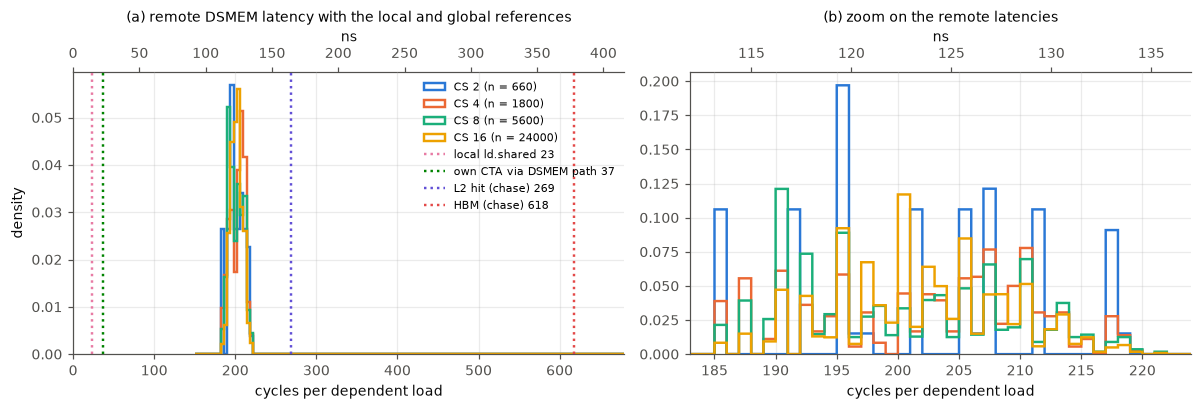

,median,p5,p95,mean,std,n,min,max,median vs CS 2 (%)
cs,,,,,,,,,
2,201.7,185.2,217.2,201.3,9.5,660,185.2,218.7,0.0
4,204.6,187.0,215.2,202.3,9.0,1800,185.5,219.1,1.4
8,199.9,187.4,214.7,200.5,8.7,5600,185.7,221.8,-0.9
16,201.9,190.9,213.4,201.9,7.0,24000,185.9,221.9,0.1


In [3]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.1, 1]})
d = MAIN[MAIN.policy == "Default"]
for i, cs in enumerate(CSS[1:]):
    x = d[d.cs == cs].cycles_per_hop
    a.hist(x, bins=np.arange(150, 700, 4), histtype="step", density=True, color=C[i], lw=1.6, label=f"CS {cs} (n = {len(x)})")
    b.hist(x, bins=np.arange(150, 700, 1), histtype="step", density=True, color=C[i], lw=1.6)
for ax in (a, b):
    for v, lab, col in [(LDS, f"local ld.shared {LDS:.0f}", C[4]), (SELF1, f"own CTA via DSMEM path {SELF1:.0f}", C[5]),
                        (L2, f"L2 hit (chase) {L2:.0f}", C[6]), (HBM, f"HBM (chase) {HBM:.0f}", C[7])]:
        ax.axvline(v, ls=":", color=col, lw=1.6, label=lab)
    ax.set_xlabel("cycles per dependent load")
a.set_xlim(0, 680); a.set_ylabel("density"); a.set_title("(a) remote DSMEM latency with the local and global references", fontsize=9)
lo, hi = d.cycles_per_hop.quantile([0.0005, 0.9995])
b.set_xlim(np.floor(lo) - 2, np.ceil(hi) + 2); b.set_title("(b) zoom on the remote latencies", fontsize=9)
a.legend(fontsize=7, loc="upper right"); ns_axis(a, "x"); ns_axis(b, "x")
plt.tight_layout(); plt.show()
t = stats(d, ["cs"], "cycles_per_hop")
t["min"] = d.groupby("cs").cycles_per_hop.min(); t["max"] = d.groupby("cs").cycles_per_hop.max()
t["median vs CS 2 (%)"] = 100 * (t["median"] / t["median"].loc[2] - 1)
display(t.style.format(precision=1).set_caption("Remote pairs, ld.shared::cluster (offset + add), stride-1 chain, Default policy: cycles per load"))

**Reading Fig. 1.** A dependent load from another CTA's shared memory takes **about 200 cycles at every cluster size**. Median of `ld_cluster` (offset chain, one `add` per hop) over all remote pairs (Default policy):

| cluster size | median, cycles | p5–p95, cycles |
|---|---|---|
| 2 | 201.7 | 185.2–217.2 |
| 4 | 204.6 | 187.0–215.2 |
| 8 | 199.9 | 187.4–214.7 |
| 16 | 201.9 | 190.9–213.4 |

Every pair value lies between 185 and 222 cycles. Compared with the references on the same chip:
- local `ld.shared`: 23 cycles, i.e. 8.7 times faster;
- the own CTA through the DSMEM path: 37 cycles (32 in the address form);
- an L2 hit: 269 cycles, i.e. 67 cycles *slower* than a remote load;
- HBM: 618 cycles.

The medians differ between cluster sizes by up to 5 cycles. That is not an effect of cluster size: 4.2 shows that every pair's latency is fixed by its two SMs, and the cluster sizes simply use different SM sets (for example, CS 4 and 8 include the slower SMs of the 12-SM GPC).

### 4.2 Scheduling policy, chain and placement (Fig. 2)

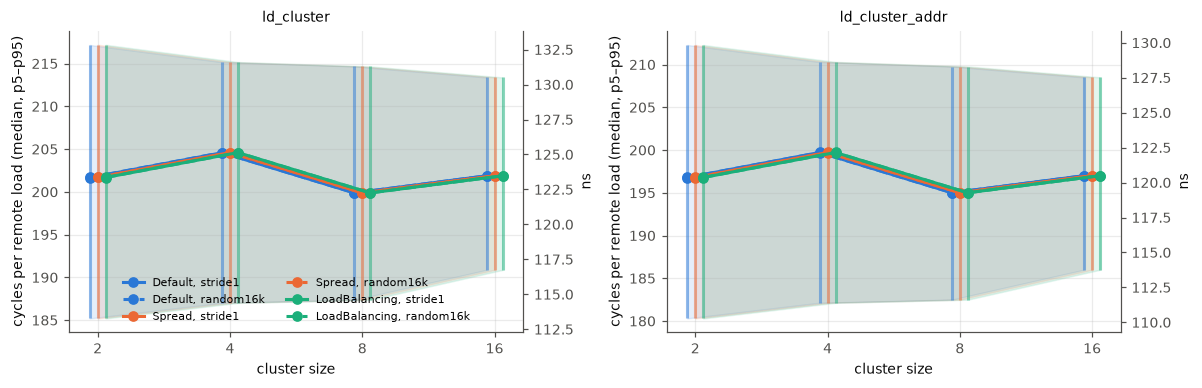

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for j, var in enumerate(["ld_cluster", "ld_cluster_addr"]):
    ax = axs[j]
    for i, pol in enumerate(POL):
        for k, (chain, ls) in enumerate([("stride1", "-"), ("random16k", "--")]):
            s = stats(REM[(REM.variant == var) & (REM.policy == pol) & (REM.chain == chain)], ["cs"], "cycles_per_hop")
            x = np.log2(s.index) + (i - 1) * 0.06
            ax.plot(x, s["median"], ls=ls, marker="o", color=C[i], label=f"{pol}, {chain}")
            ax.fill_between(x, s.p5, s.p95, color=C[i], alpha=0.12 if k == 0 else 0.0)
            if k == 1:
                ax.errorbar(x, s["median"], yerr=[s["median"] - s.p5, s.p95 - s["median"]], fmt="none", ecolor=C[i], alpha=0.5)
    ax.set_xticks(np.log2(CSS[1:])); ax.set_xticklabels(CSS[1:]); ax.set_xlabel("cluster size")
    ax.set_ylabel("cycles per remote load (median, p5–p95)"); ax.set_title(var, fontsize=9); ns_axis(ax)
axs[0].legend(fontsize=7, ncol=2, loc="lower center")
plt.tight_layout(); plt.show()
t = REM[REM.variant.isin(["ld_cluster", "ld_cluster_addr"])].groupby(["variant", "chain", "policy", "cs"]).cycles_per_hop.median().unstack("cs")
display(t.style.format(precision=1).set_caption("Median cycles per remote load by variant, chain, policy and cluster size"))

**Scheduling policy and chain.** With one CTA per SM, the three policies give the same median at every cluster size to within 0.05 cycles. The random 16-KiB chain gives the same values as the stride-1 chain, to the hundredth of a cycle. There is no sign of prefetching, combining or bank effects for a single outstanding load, and the order of addresses does not matter. The address form (`ld_cluster_addr`, no `add` in the chain) is 4.9 cycles faster at every cluster size, exactly the dependent integer add of the offset form.

In [5]:
# Placement: which pairs are slower? TPC relation, GPC, and the rank matrix at CS 16
d = MAIN[MAIN.policy == "Default"].copy()
t = d.groupby(["cs", "pair"]).cycles_per_hop.describe(percentiles=[0.05, 0.5, 0.95])[["count", "5%", "50%", "95%"]]
display(t.style.format(precision=1).set_caption("Remote pairs by TPC relation (TPC = SMs 2t, 2t+1)"))
g = d[d.cs == 16].groupby("gpc_src").cycles_per_hop.describe(percentiles=[0.05, 0.5, 0.95])[["count", "5%", "50%", "95%"]]
display(g.style.format(precision=1).set_caption("CS 16 remote pairs by GPC (all 16 SMs of a cluster lie in one GPC)"))

,count,5%,50%,95%
gpc_src,,,,
1,3600.0,190.9,200.4,209.9
2,3600.0,190.9,200.4,209.9
3,3600.0,190.9,202.4,213.4
4,2400.0,190.9,204.9,216.9
5,3600.0,190.9,202.4,213.4
6,3600.0,190.9,202.4,213.4
7,3600.0,190.9,202.4,213.4


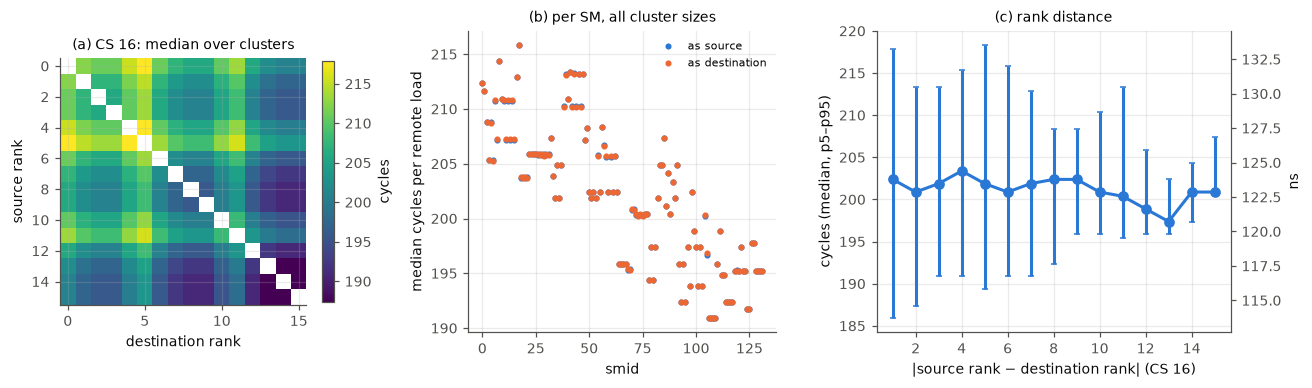

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.15]})
c16 = MAIN[(MAIN.cs == 16) & (MAIN.policy == "Default")]
m = c16.groupby(["src_rank", "dst_rank"]).cycles_per_hop.median().unstack()
s16 = CH[(CH.cs == 16) & (CH.variant == "ld_cluster") & (CH.chain == "stride1") & (CH.policy == "Default")]
m_all = s16.groupby(["src_rank", "dst_rank"]).cycles_per_hop.median().unstack()
lo, hi = np.nanpercentile(m.values, [1, 99])
im = axs[0].imshow(m_all.where(m_all.index.values[:, None] != m_all.columns.values[None, :]), cmap="viridis", vmin=lo, vmax=hi)
axs[0].set_xlabel("destination rank"); axs[0].set_ylabel("source rank"); axs[0].set_title("(a) CS 16: median over clusters", fontsize=9)
plt.colorbar(im, ax=axs[0], shrink=0.8, label="cycles")
# per-SM view: mean latency as a source and as a destination (all CS > 1, Default)
d = MAIN[MAIN.policy == "Default"]
src = d.groupby("smid_src").cycles_per_hop.median(); dst = d.groupby("smid_dst").cycles_per_hop.median()
axs[1].plot(src.index, src.values, ".", label="as source"); axs[1].plot(dst.index, dst.values, ".", label="as destination")
axs[1].set_xlabel("smid"); axs[1].set_ylabel("median cycles per remote load"); axs[1].legend(fontsize=7)
axs[1].set_title("(b) per SM, all cluster sizes", fontsize=9)
# rank distance |src − dst| at CS 16
c16 = c16.assign(dist=(c16.src_rank - c16.dst_rank).abs())
s = stats(c16, ["dist"], "cycles_per_hop")
axs[2].errorbar(s.index, s["median"], yerr=[s["median"] - s.p5, s.p95 - s["median"]], fmt="o-", capsize=2)
axs[2].set_xlabel("|source rank − destination rank| (CS 16)"); axs[2].set_ylabel("cycles (median, p5–p95)")
axs[2].set_title("(c) rank distance", fontsize=9); ns_axis(axs[2])
plt.tight_layout(); plt.show()

**Placement.**
- TPC mates (the two SMs of one TPC) are not faster than SMs on different TPCs (table above).
- Panel (a): the CS-16 rank matrix has no diagonal structure.
- Panel (b): every SM has a characteristic offset, and it is the same whether the SM is the source or the destination.
- Panel (c): the rank distance has no systematic effect.

This suggests an additive model, tested below.

pairs,SMs,c (cycles),residual std,max |residual|,raw std of pair medians
1874,132,197.088,0.036,0.585,7.025


,count,mean,std
other TPC,1742,0.003,0.016
same TPC,132,-0.037,0.116


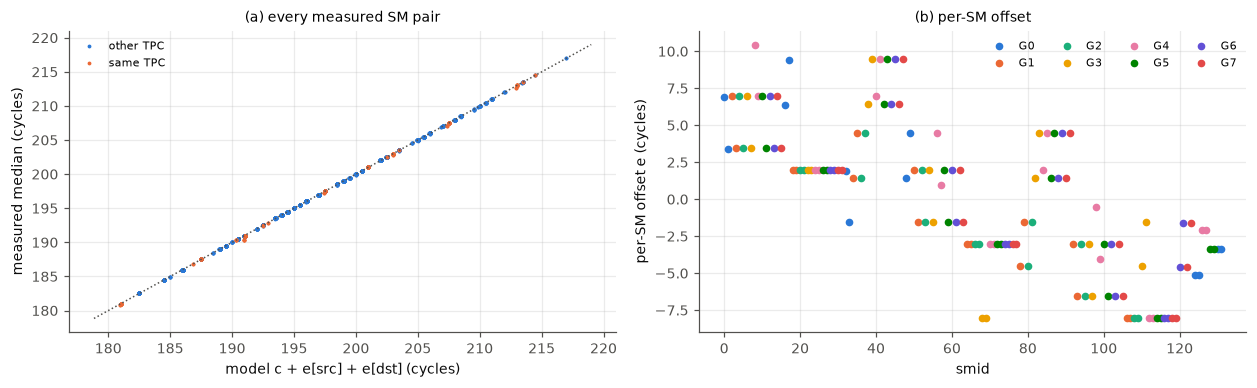

,G0,G1,G2,G3,G4,G5,G6,G7
slot,,,,,,,,
0,5.2,5.2,5.2,5.2,8.7,5.2,5.2,5.2
1,7.9,2.0,2.0,2.0,2.0,2.0,2.0,2.0
2,0.2,3.0,3.0,8.0,8.2,8.0,8.0,8.0
3,3.0,0.2,0.2,0.2,2.7,0.2,0.2,0.2
4,,-3.0,-3.0,-8.0,-3.0,-3.0,-3.0,-3.0
5,,-3.0,-3.0,3.0,3.2,3.0,3.0,3.0
6,,-4.8,-4.8,-4.8,-2.3,-4.8,-4.8,-4.8
7,,-8.0,-8.0,-3.0,-8.1,-8.0,-8.0,-8.0
extra (TPC 60),,,,,,,-3.1,


largest offset difference between the two SMs of one TPC: 3.50 cycles; offsets span -8.1 … 10.5; fastest / slowest measured pair 180.8 / 217.0 cycles


In [7]:
# Additive model t(src, dst) = c + e[src] + e[dst] over the median of every measured SM pair (address form, stride-1 chain,
# all policies, cluster sizes and launches); the offsets are constrained to sum to zero.
r = REM[(REM.variant == "ld_cluster_addr") & (REM.chain == "stride1")]
p = r.groupby(["smid_src", "smid_dst"]).cycles_per_hop.median()
sms = sorted(set(p.index.get_level_values(0)) | set(p.index.get_level_values(1)))
ix = {s: i for i, s in enumerate(sms)}
n = len(sms)
A = np.zeros((len(p) + 1, n + 1))
for k, (s_, d_) in enumerate(p.index):
    A[k, ix[s_]] += 1; A[k, ix[d_]] += 1; A[k, n] = 1
A[-1, :n] = 1
x = np.linalg.lstsq(A, np.r_[p.values, 0.0], rcond=None)[0]
E, C0 = pd.Series(x[:n], index=sms), x[n]
res = pd.Series(p.values - A[:-1] @ x, index=p.index)
kind = pd.Series(np.where(np.array([s_ // 2 == d_ // 2 for s_, d_ in p.index]), "same TPC", "other TPC"), index=p.index)
display(pd.DataFrame({"pairs": [len(p)], "SMs": [n], "c (cycles)": [C0], "residual std": [res.std()], "max |residual|": [res.abs().max()],
                      "raw std of pair medians": [p.std()]}).style.format(precision=3).hide(axis="index"))
display(res.groupby(kind).agg(["count", "mean", "std"]).style.format(precision=3).set_caption("Residuals by pair relation (cycles)"))
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 3.6))
for i, kd in enumerate(["other TPC", "same TPC"]):
    m = kind == kd
    a.plot(A[:-1][m.values] @ x, p.values[m.values], ".", ms=3, color=C[i], label=kd)
lim = [p.min() - 2, p.max() + 2]
a.plot(lim, lim, ":", color=INK2, lw=1); a.set_xlabel("model c + e[src] + e[dst] (cycles)"); a.set_ylabel("measured median (cycles)")
a.legend(fontsize=7); a.set_title("(a) every measured SM pair", fontsize=9)
g = SMAP.loc[E.index, "gpc"]
for gg in sorted(g.unique()):
    m = g == gg
    b.plot(E.index[m], E[m], "o", ms=4, color=C[gg % len(C)], label=f"G{gg}")
b.set_xlabel("smid"); b.set_ylabel("per-SM offset e (cycles)"); b.legend(fontsize=7, ncol=4); b.set_title("(b) per-SM offset", fontsize=9)
plt.tight_layout(); plt.show()
# offsets by GPC and TPC slot: slot = rank of the TPC among its GPC's TPCs 0-59 (ascending TPC number); TPCs 60-65 = "extra"
tp = pd.DataFrame({"e": E, "gpc": g, "tpc": E.index // 2})
slot = {}
for gg, grp in tp.groupby("gpc"):
    reg = sorted(t for t in grp.tpc.unique() if t < 60)
    for t in grp.tpc.unique():
        slot[t] = str(reg.index(t)) if t < 60 else f"extra (TPC {t})"
tp["slot"] = tp.tpc.map(slot)
tab = tp.groupby(["slot", "gpc"]).e.mean().unstack("gpc")
tab.columns = [f"G{c}" for c in tab.columns]
display(tab.style.format(precision=1, na_rep="").set_caption("Per-SM offset e (cycles, mean of the TPC's two SMs) by GPC and TPC slot"))
print(f"largest offset difference between the two SMs of one TPC: {tp.groupby('tpc').e.agg(lambda v: v.max() - v.min()).max():.2f} cycles; "
      f"offsets span {E.min():.1f} … {E.max():.1f}; fastest / slowest measured pair {p.min():.1f} / {p.max():.1f} cycles")

**An additive per-SM model explains every pair.** We fit the median latency of every measured (source SM, destination SM) pair, address form, as

$$t(\mathrm{src}, \mathrm{dst}) = c + e_{\mathrm{src}} + e_{\mathrm{dst}},$$

with one constant *c* and one offset per SM, the same offset whether the SM sends or receives.
- **Fit.** It describes all measured pairs with a residual standard deviation of 0.04 cycles and a largest residual below 1 cycle (above).
- **Pair relation.** TPC-mate pairs fit as well as any other pair (residuals ≤ 0.6 cycles): there is no shortcut inside a TPC.
- **Size of the offsets.** They span about −8 to +10.5 cycles, so the fastest pair costs about 181 and the slowest about 217 cycles.
- **Structure of the offsets.** They depend on the position (slot) of the TPC within its GPC, and slots repeat across GPCs (table). The offsets are identical slot by slot in G1 and G2, and identical in G5, G6 and G7; these two families differ in slots 2 and 5. G3 and G4 deviate from G5–G7 in two or three slots, and the 12-SM GPC G0 has its own pattern. The two SMs of one TPC have equal offsets in most TPCs (largest difference 3.5 cycles).

This is the signature of a GPC-level crossbar (or hub) that every request and every reply crosses. Each SM sits at a fixed distance from it, and there is no direct path between neighbouring SMs.

### 4.3 Load variants (Fig. 3)

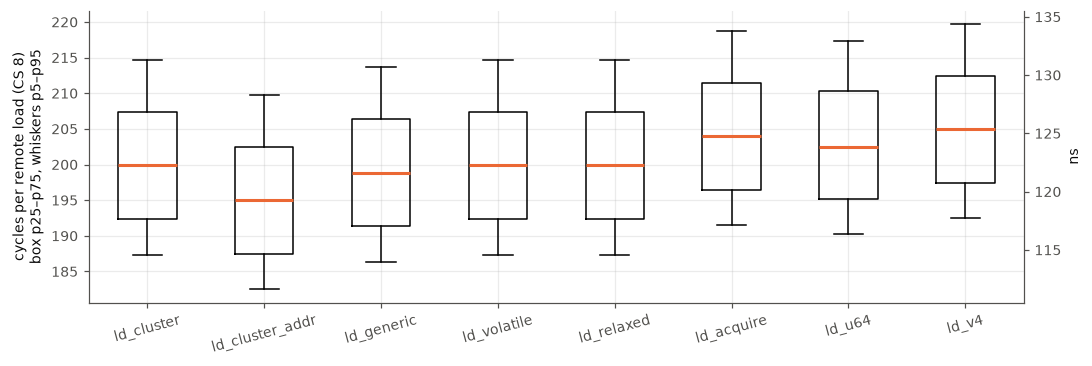

In [8]:
VARS = ["ld_cluster", "ld_cluster_addr", "ld_generic", "ld_volatile", "ld_relaxed", "ld_acquire", "ld_u64", "ld_v4"]
d8 = REM[(REM.cs == 8) & (REM.policy == "Default") & (REM.chain == "stride1")]
fig, ax = plt.subplots(figsize=(10, 3.4))
data = [d8[d8.variant == v].cycles_per_hop.values for v in VARS]
ax.boxplot(data, whis=(5, 95), showfliers=False, widths=0.5, medianprops={"color": C[1], "lw": 2})
ax.set_xticks(range(1, len(VARS) + 1)); ax.set_xticklabels(VARS, rotation=15)
ax.set_ylabel("cycles per remote load (CS 8)\nbox p25–p75, whiskers p5–p95"); ns_axis(ax)
plt.tight_layout(); plt.show()
t = CH[(CH.chain == "stride1") & (CH.policy == "Default")].copy()
t["kind"] = np.where(t.pair == "self", "self", "remote")
tt = t.groupby(["variant", "kind", "cs"]).cycles_per_hop.median().unstack("cs").reindex(VARS, level=0)
display(tt.style.format(precision=1, na_rep="").set_caption("Median cycles per load by variant (stride-1 chain, Default policy); "
                                                         "self = the CTA's own memory through the DSMEM path"))

**Load forms (Fig. 3, table).** Relative to `ld_cluster` (offset chain):
- **Generic pointer** (`map_shared_rank`, CUDA C++): 1 cycle faster. Its address is a single 64-bit add in front of a generic `LD.E`, one instruction less than `mapa` + `ld.shared::cluster` in the offset form.
- **`ld.volatile` and `ld.relaxed.cluster`:** identical, although they compile to `LD.E.STRONG.SYS` / `LD.E.STRONG.GPU`. The strong forms cost nothing on this path.
- **`ld.acquire.cluster`:** +4 cycles, from the `CCTL.IVALL` (L1 invalidation) that follows every acquire load.
- **8-B and 16-B loads:** +2.5–3.3 and +5.0–5.1 cycles remote, +1.7 and +5.2 on the own CTA. The width barely matters for latency.

All of these offsets are the same on every pair and at every cluster size.

### 4.4 Latency under load (variant f)

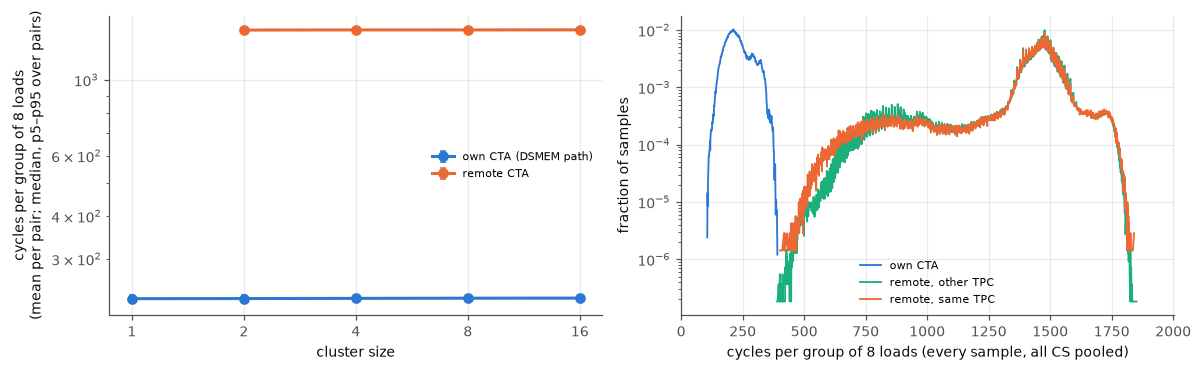

In [9]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.4))
for i, (kind, lab) in enumerate([("self", "own CTA (DSMEM path)"), ("remote", "remote CTA")]):
    x = LO[(LO.pair == "self") if kind == "self" else (LO.pair != "self")]
    s = stats(x, ["cs"], "cta_mean_cycles_per_group")
    a.errorbar(np.log2(s.index), s["median"], yerr=[s["median"] - s.p5, s.p95 - s["median"]], fmt="o-", color=C[i], label=lab, capsize=2)
a.set_xticks(np.log2(CSS)); a.set_xticklabels(CSS); a.set_xlabel("cluster size"); a.set_yscale("log")
a.set_ylabel("cycles per group of 8 loads\n(mean per pair; median, p5–p95 over pairs)"); a.legend(fontsize=7)
h = LH.assign(kind=np.where(LH.same_sm == 1, "own CTA", np.where(LH.same_tpc == 1, "remote, same TPC", "remote, other TPC")))
for i, (kind, g) in enumerate(h.groupby("kind")):
    g = g.groupby("cycles")["count"].sum()
    b.plot(g.index, g.values / g.values.sum(), color=C[[0, 2, 1][i]], lw=1.2, label=kind)
b.set_xlim(0, h.cycles[h["count"] > 0].quantile(0.999) * 1.1 if len(h) else 1); b.set_yscale("log")
b.set_xlabel("cycles per group of 8 loads (every sample, all CS pooled)"); b.set_ylabel("fraction of samples"); b.legend(fontsize=7)
plt.tight_layout(); plt.show()
t = LO.assign(kind=np.where(LO.pair == "self", "self", "remote")).groupby(["kind", "cs"])[
    ["cta_mean_cycles_per_group", "cta_p5", "cta_p50", "cta_p95"]].median()
display(t.style.format(precision=1).set_caption("Loaded latency: 1024 threads × 8 independent 4-B loads per group (medians over pairs)"))

**Under load (variant f).** When all 1024 threads of the source keep 8 loads each in flight (32 KiB requested at once), a group of 8 loads takes **≈ 1400 cycles** from issue to the last value (p5–p95 within a pair: about 810–1640 cycles). That is seven times the zero-load latency.
- It is the same for every cluster size, for TPC mates and other pairs, and for every SM. The limit is therefore the source SM's injection into the SM-to-SM network, not the path to a particular destination.
- The same stream pointed at the own CTA through the DSMEM path takes 230 cycles per group: the own CTA's shared memory is not the bottleneck.
- The counters confirm that own-CTA accesses never leave the SM (4.7).

The group time is a queueing time. It measures the throughput limit, not the latency of an isolated load (Fig. 1); the bandwidth itself is measured separately.

### 4.5 Remote store visibility (Fig. 4)

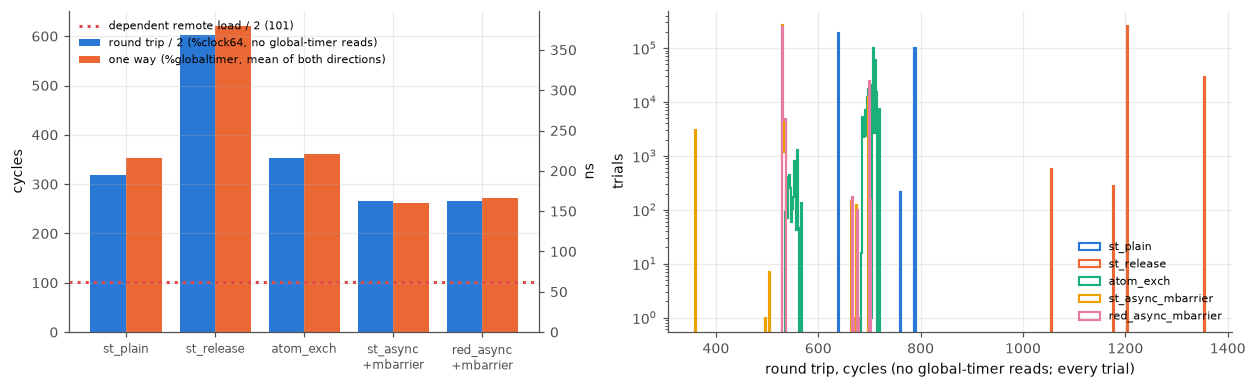

,round trip median,round trip p5,round trip p95,share > median + 100,"one way q→p (ns, mean)","one way p→q (ns, mean)",round trip with timer reads
variant,,,,,,,
st_plain,639.00,639.00,789.00,0.35,212.07,219.64,649.00
st_release,1205.00,1205.00,1355.00,0.10,375.47,383.78,1217.00
atom_exch,707.00,689.00,714.00,0.00,214.98,226.01,714.00
st_async_mbarrier,530.00,530.00,534.00,0.04,156.74,164.41,537.00
red_async_mbarrier,531.00,531.00,700.00,0.09,160.00,172.53,538.00


In [10]:
METH = ["st_plain", "st_release", "atom_exch", "st_async_mbarrier", "red_async_mbarrier"]
gt, ng = VI[~VI.variant.str.endswith("_nogt")], VI[VI.variant.str.endswith("_nogt")].assign(variant=lambda x: x.variant.str[:-5])
rt = ng.groupby("variant").round_trip_cycles
ow = gt.groupby("variant")[["one_way_ns", "one_way_back_ns"]].mean().mean(axis=1) * MHZ / 1e3
LOADRT = MAIN[MAIN.policy == "Default"].cycles_per_hop.median()
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1, 1.2]})
x = np.arange(len(METH))
a.bar(x - 0.2, rt.median().reindex(METH) / 2, 0.4, color=C[0], label="round trip / 2 (%clock64, no global-timer reads)")
a.bar(x + 0.2, ow.reindex(METH), 0.4, color=C[1], label="one way (%globaltimer, mean of both directions)")
a.axhline(LOADRT / 2, ls=":", color=C[7], label=f"dependent remote load / 2 ({LOADRT / 2:.0f})")
a.set_xticks(x); a.set_xticklabels([m.replace("_mbarrier", "\n+mbarrier") for m in METH], fontsize=8)
a.set_ylabel("cycles"); a.legend(fontsize=7, loc="upper left"); ns_axis(a)
for i, m in enumerate(METH):
    v = ng[ng.variant == m].round_trip_cycles
    b.hist(v, bins=np.arange(v.quantile(0.001) - 5, v.quantile(0.999) + 5, 2), histtype="step", color=C[i], lw=1.4, label=m)
b.set_xlabel("round trip, cycles (no global-timer reads; every trial)"); b.set_ylabel("trials"); b.set_yscale("log"); b.legend(fontsize=7)
plt.tight_layout(); plt.show()
t = ng.groupby(["variant", "cs", "dst_rank"]).round_trip_cycles.median().unstack(["cs", "dst_rank"]).reindex(METH)
display(t.style.format(precision=0).set_caption("Median round trip (cycles, no global-timer reads) by cluster size and peer rank (initiator = rank 0)"))
s = pd.DataFrame({"round trip median": rt.median(), "round trip p5": rt.quantile(0.05), "round trip p95": rt.quantile(0.95),
                  "share > median + 100": ng.groupby("variant").apply(lambda g: (g.round_trip_cycles > g.round_trip_cycles.median() + 100).mean()),
                  "one way q→p (ns, mean)": gt.groupby("variant").one_way_ns.mean(), "one way p→q (ns, mean)": gt.groupby("variant").one_way_back_ns.mean(),
                  "round trip with timer reads": gt.groupby("variant").round_trip_cycles.median()}).reindex(METH)
display(s.style.format(precision=2).set_caption("Store → visibility, all cluster sizes and pairs pooled"))

**Remote store visibility (Fig. 4).**

| method | round trip, cycles | one way, `%globaltimer` | one way ≈ round trip / 2 |
|---|---|---|---|
| `st.async` + mbarrier | 530 | 157–164 ns | 265 cycles |
| `red.async` + mbarrier | 531 | ≈ 160–173 ns | 266 cycles |
| plain `st.shared::cluster` + local poll | 639 | 212–220 ns | 320 cycles |
| `atom.exch` + local poll | 694–712 | ≈ 215–226 ns | ≈ 350 cycles |
| `st.release.cluster` + local poll | 1205 | 375–384 ns | 603 cycles |

Round trips are measured without global-timer reads.
- **Cheapest hand-off.** `st.async` / `red.async`, where the store completes a transaction on the receiver's mbarrier, is 109 cycles cheaper per round trip than a plain store polled in shared memory.
- **Release.** A release store doubles the cost: every release is a GPU-scope memory barrier on this GPU.
- **Placement.** All methods have the same round trip at every cluster size and for TPC mates and other pairs.
- **Comparison with a load.** Even the fastest one-way hand-off (≈ 265 cycles) exceeds a complete dependent remote *load* (≈ 200 cycles round trip). A posted store must be committed in the destination SM and then observed by the destination's poll or barrier wait, which adds the waiter's detection time to the transfer.

**Quantised round trips.** The plain, release, `st.async` and `red.async` hand-offs have a second mode exactly 150 cycles (plain, release) or 169 cycles (mbarrier methods) above their main value; the atomic exchange spreads over 685–720 cycles without such a mode. It occurs in 34 % of the plain-store trials, 10 % of release, 4–9 % of `st.async`/`red.async`. `st.async` also has a 1 % mode 169 cycles *below* (361). With `%globaltimer` reads inside the loop the slow mode is more frequent (plain: 47 %) and the per-cluster pattern alternates every two trials. The steps are discrete, not a continuous tail, so the hand-off appears to be quantised to a fixed time slot of about 150–170 SM cycles (≈ 90–100 ns) somewhere on the path; we have not identified which unit.

### 4.6 Per-hop series (Fig. 5)

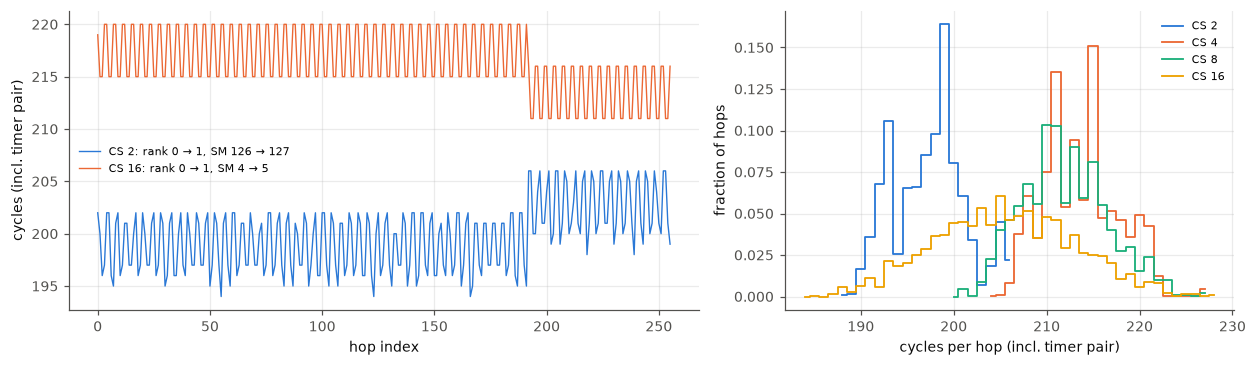

In [11]:
TP = BA[BA.level == "timer_pair"].cycles_per_hop.median()
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 3.4), gridspec_kw={"width_ratios": [1.4, 1]})
for i, cs in enumerate([2, 16]):
    f = FI[(FI.cs == cs) & (FI.pair != "self")]
    one = f[(f.launch_idx == f.launch_idx.min()) & (f.cluster_id == 0)]
    k = one.groupby(["src_rank", "dst_rank"]).ngroups
    pr = one[(one.src_rank == 0) & (one.dst_rank == 1)]
    a.plot(pr.hop_idx, pr.cycles, lw=0.9, color=C[i], label=f"CS {cs}: rank 0 → 1, SM {pr.smid_src.iloc[0]} → {pr.smid_dst.iloc[0]}")
f = FI[FI.pair != "self"]
a.set_xlabel("hop index"); a.set_ylabel("cycles (incl. timer pair)"); a.legend(fontsize=7)
for i, cs in enumerate(CSS[1:]):
    v = FI[(FI.cs == cs) & (FI.pair != "self")].cycles
    vc = v.value_counts(normalize=True).sort_index()
    b.plot(vc.index, vc.values, drawstyle="steps-mid", color=C[i], lw=1.2, label=f"CS {cs}")
b.set_xlabel("cycles per hop (incl. timer pair)"); b.set_ylabel("fraction of hops"); b.legend(fontsize=7)
plt.tight_layout(); plt.show()
t = FI.assign(kind=np.where(FI.pair == "self", "self", "remote")).groupby(["kind", "cs"]).cycles.describe(percentiles=[0.01, 0.5, 0.99])
display(t[["count", "min", "1%", "50%", "99%", "max", "std"]].style.format(precision=1).set_caption(
    "Per-hop cycles of the fine pass, including the timer pair (own CTA: 40 per hop vs 36.9 averaged over 4096 hops)"))

**Per hop (Fig. 5).** Individually timed hops show that each 4096-hop average hides a small, fully deterministic structure:
- **Reproducible.** On a given pair the per-hop latency follows a fixed pattern of a few cycles that is identical in all five launches (correlation 1.00). The CS-2 pair in panel (a) alternates between ≈ 202 and ≈ 197 cycles with a period of four hops and steps up by ≈ 4 cycles at hop 192; the CS-16 pair steps down at the same hop.
- **Address bits.** The fine pass reads byte offsets 256–1279 of the destination's chain, so hop 192 is offset 1024 and the four-hop period is address bit 3. Within this window only address bits 3 and 10 change the latency (bits 8 and 9 only through their correlation with bit 10 here). Their effect is a fixed property of the (source SM, destination SM) pair: 0 to about ±5 cycles, with a sign that differs from pair to pair, so it cancels over many pairs. Per-pair means for the four combinations of the two bits halve the within-pair standard deviation (2.2 → 1.2 cycles). The 4096-hop averages cover whole chains and are not affected.
- **Range.** There are no slow outliers: the maximum is 228 cycles over 1.75 million hops.
- **Own CTA.** Through the DSMEM path every hop costs exactly 40 cycles: the 4096-hop value of 36.9 plus ≈ 3 cycles for the timer pair.

### 4.7 Counter check and SASS

In [12]:
if not QUICK:
    n = ncu[ncu.run_id == ncu.run_id.max()].copy()
    n["expected remote loads"] = n.chase * n.nclusters * n.cs * (n.cs - 1) * 4160  # 64 warm-up + 4096 timed hops per remote pair
    cols = {"sm__sass_inst_executed_op_dshared_ld.sum": "DSMEM load instructions",
            "l1tex__t_requests_pipe_lsu_mem_dshared_op_ld.sum": "DSMEM load requests",
            "l1tex__m_l1tex2xbar_write_bytes_mem_dshared_op_ld.sum": "bytes SM → network",
            "l1tex__m_xbar2l1tex_read_bytes_mem_dshared_op_ld.sum": "bytes network → SM",
            "l1tex__m_l1tex2xbar_req_cycles_active_mem_dshared_loopback.sum": "loopback active cycles",
            "lts__t_sectors_srcunit_tex.sum": "L2 sectors requested by SMs"}
    t = n[["cs", "nclusters", "chase", "expected remote loads"] + [c for c in cols if c in n]].rename(columns=cols)
    t = t.apply(pd.to_numeric, errors="coerce")
    t["bytes out per load"] = t["bytes SM → network"] / t["DSMEM load instructions"]
    t["bytes in per load"] = t["bytes network → SM"] / t["DSMEM load instructions"]
    t["launch"] = np.where(t.chase == 1, "chase", "all-exit baseline")
    display(t.drop(columns="chase").set_index(["cs", "launch"]).T.style.format(precision=0, na_rep="-")
            .set_caption("Nsight Compute, K1 ld_cluster, 2 clusters per launch (kernel replay, caches and clocks untouched)"))

In [13]:
# SASS of the timed loop of k1_chase<ld_cluster> (from the binary's cuobjdump dump): the first timed hops
sass = open("results/sass/dsmem_lat.sass").read().split("Function : ")
k = [s for s in sass if s.startswith("_Z8k1_chaseILi0E")][0].splitlines()
i = next(j for j, l in enumerate(k) if "CS2R" in l and "SR_CLOCKLO" in l)
print("\n".join(l.strip() for l in k[i:i + 16]))

/*0ab0*/                   CS2R R8, SR_CLOCKLO ;
/*0ac0*/                   IADD3 R6, P2, R8, R5, RZ ;
/*0ad0*/                   MOV R7, RZ ;
/*0ae0*/                   IMAD.X R5, RZ, RZ, R9, P2 ;
/*0af0*/                   IMAD.IADD R15, R3, 0x1, R12 ;
/*0b00*/                   MOV R14, R15 ;
/*0b10*/                   MOV R15, R4 ;
/*0b20*/                   LD.E R14, [R14] ;
/*0b30*/                   IMAD.IADD R9, R3, 0x1, R14 ;
/*0b40*/                   MOV R8, R9 ;
/*0b50*/                   MOV R9, R4 ;
/*0b60*/                   LD.E R8, [R8] ;
/*0b70*/                   IMAD.IADD R11, R3, 0x1, R8 ;
/*0b80*/                   MOV R10, R11 ;
/*0b90*/                   MOV R11, R4 ;
/*0ba0*/                   LD.E R10, [R10] ;


**Counters.**
- **Instruction counts.** Nsight Compute counts exactly 4160 `dshared` load instructions (64 warm-up + 4096 timed hops) per *remote* pair: 2 × 2 × 4160 at CS 2 and 2 × 56 × 4160 at CS 8. Hops on the own CTA through the DSMEM path are not counted as DSMEM traffic, and the loopback activity counter stays 0: such accesses never leave the SM.
- **Bytes.** Every 4-B remote load moves 32 B out of the SM (`l1tex2xbar` write bytes) and 32 B back in (`xbar2l1tex` read bytes), i.e. one 32-B request packet and one 32-B response packet.
- **L2.** The L2 sees only the handful of sectors that the launch's result writes produce (the same order as in the all-exit launch), against hundreds of thousands of remote loads: the chase never touches L2.

The SASS excerpt above is the start of the timed loop of `ld_cluster`: the clock read (`CS2R SR_CLOCKLO`), then per hop the `add` of the offset (`IMAD.IADD`), the move of the window base `SR_SWINHI` into the high address word, and the generic `LD.E`.

**Rare doubled measurements.** 54 of the 1.09 million pair measurements (0.005 %) took almost exactly twice their usual time (≈ 385–411 cycles).
- They came in 6 bursts in 6 CS-16 launches. In each burst several clusters running at the same moment each had exactly one pair doubled, the neighbouring pairs normal.
- The clock samples showed no throttle reason, and nothing in the kernels changes at those moments. The cause lies outside the measured path (an event affecting the whole GPU for about a millisecond) and was not identified.
- The rows are kept in every statistic; they do not change any median or p95 shown here.

## 5. Insights

- **Flat, fast SM-to-SM latency.**
  - A dependent load from another CTA's shared memory costs ≈ 200 SM cycles (≈ 120 ns at 1635 MHz), whatever the cluster size from 2 to 16, the scheduling policy or the order of addresses.
  - That is 8–9 local shared-memory accesses, ≈ 70 cycles less than an L2 hit and a third of an HBM access.
  - Growing a cluster costs no latency, so on this chip cluster size should be chosen for occupancy and data reuse, not to keep accesses close.
- **The latency structure is additive per SM: a GPC-level hub.**
  - The latency of every pair equals a constant (≈ 197 cycles) plus a fixed offset of the source SM plus the *same kind* of offset of the destination SM, to within 0.04 cycles.
  - The offsets (−8…+10.5 cycles) depend on the TPC's slot in its GPC and repeat across GPCs.
  - TPC mates gain nothing. There is no neighbour shortcut and no measurable step between groups of TPCs: requests and replies cross one central point per GPC, and wire or pipeline length to that point is the only distance term. For a 3D-stacked design this means the in-GPC network behaves like a crossbar whose port distances differ by up to ≈ ±9 cycles per SM (≈ ±5 % of a pair's latency each): placement inside a GPC barely matters (≤ 36 cycles between the best and the worst pair).
- **The DSMEM path itself has a fixed cost.**
  - Addressing the own CTA through the cluster window costs 32 cycles instead of 23, and the access never leaves the SM (ncu: no DSMEM traffic, no loopback activity).
  - A remote access adds ≈ 165 cycles for the trip through the network and the remote SM.
  - Every 4-B remote load moves a 32-B request and a 32-B response.
- **Instruction form matters little.**
  - Address arithmetic in the chain (+5 cycles for the dependent `add` of an offset form) and the acquire qualifier (+4, the L1 invalidation) are the only visible costs.
  - `volatile`/`relaxed` are free, and 8- or 16-B loads cost ≤ 5 cycles more than 4-B loads.
  - The generic pointer CUDA C++ produces is as fast as explicit `ld.shared::cluster`.
- **Under load the source's injection is the limit.** With 32 KiB requested at once, a group of 8 loads per thread takes ≈ 1400 cycles, equally for every destination and every cluster size, while the same stream on the own CTA's memory takes 230 cycles.
- **Hand-offs: use the mbarrier-signalled stores.**
  - `st.async` / `red.async` completing a transaction on the receiver's mbarrier make data visible ≈ 265 cycles after the store (530-cycle round trip).
  - Polling a plain remote store costs ≈ 320 cycles per direction, a release store ≈ 600 (every release is a GPU-scope fence), an atomic exchange ≈ 350.
  - Any hand-off costs more than a remote load round trip, because the receiver must also detect the arrival.
  - Round trips of the store and mbarrier hand-offs are quantised in steps of 150–170 cycles: a hand-off either makes a slot or waits for the next one.
- **Anomalies and limits.**
  - 0.005 % of pair measurements were doubled by GPU-wide events of about a millisecond (cause not identified).
  - Per-hop latency carries a deterministic pair-specific jitter of a few cycles.
  - The SMs that never join clusters larger than 2 (SMs 124–131) were measured only as CS-2 pairs.
  - All values are SM cycles of the issuing SM; the per-GPC SM clocks under the lock differ by < 1 %, so conversions to ns carry that uncertainty.